# ATLAS — WRI Aqueduct 4.0 | Final EDA & Merge Preparation

**Scope:** Baseline annual Aqueduct water-risk data (the existing `Aqueduct4_EDA.py` analysis), US-focused quality checks, interpretable figures, and **safe facility-level spatial extraction**. Monthly and future files are inventoried, **not silently combined** with the baseline model features.

**Outputs:** `Data/processed/wri_aqueduct_baseline_us_units.csv`, `Data/processed/wri_aqueduct_facility_features.csv` *(only when spatial join is configured)*, `Data/processed/wri_aqueduct_spatial_join_audit.csv`, and figures in `Data/processed/wri_figures/`.

**Important:** Aqueduct rows are geographic units, not IM3 facilities. A direct row-wise merge is invalid. The optional spatial join requires polygon geometry with a key matching the Aqueduct table. Check Aqueduct documentation for interpretation of sentinel values and category codes before modeling.

## 1. Setup and paths
Run this notebook from the ATLAS repository root. Set `AQUEDUCT_DIR` to the folder containing the three CSV files. Windows paths in the original EDA script are not valid inside WSL.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
REPO = Path.cwd()
AQUEDUCT_DIR = Path("/mnt/c/Users/attho/OneDrive/Desktop/College/ACM ATLAS/aqueduct-4-0-water-risk-data/Aqueduct40_waterrisk_download_Y2023M07D05/CVS")
REGISTRY_PATH = REPO / "Data/processed/im3_facility_registry.csv"
OUTPUT_DIR = REPO / "Data/processed"
FIG_DIR = OUTPUT_DIR / "wri_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Optional spatial-join configuration (leave None until verified):
BASIN_BOUNDARIES_PATH = None  # e.g. Path("Data/raw/wri/aqueduct_basins.gpkg")
BOUNDARY_JOIN_KEY = None      # column in polygon file matching AQUEDUCT_JOIN_KEY
AQUEDUCT_JOIN_KEY = None      # column in annual CSV uniquely identifying basin/unit

# Treat codes as missing for exploratory plots/model features; retain original CSV untouched.
# Confirm these codes against your Aqueduct documentation before final model training.
SENTINELS_TO_MASK = [-9999, 9999]
print("Working directory:", REPO)
print("Aqueduct CSV folder exists:", AQUEDUCT_DIR.exists())
print("Registry exists:", REGISTRY_PATH.exists())

Working directory: /mnt/c/Users/attho/OneDrive/Desktop/College/ACM ATLAS/ATLAS
Aqueduct CSV folder exists: True
Registry exists: True


## 2. Load the same three Aqueduct files used in your EDA

In [2]:
def locate_csv(fragment):
    hits = sorted(AQUEDUCT_DIR.glob(f"*{fragment}*.csv"))
    if len(hits) != 1:
        raise FileNotFoundError(f"Expected one CSV matching {fragment!r} in {AQUEDUCT_DIR}; found {len(hits)}: {hits}")
    return hits[0]

annual = pd.read_csv(locate_csv("baseline_annual"), low_memory=False)
monthly = pd.read_csv(locate_csv("baseline_monthly"), low_memory=False)
future = pd.read_csv(locate_csv("future_annual"), low_memory=False)
for name, df in [("Baseline annual", annual), ("Baseline monthly", monthly), ("Future annual", future)]:
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
print("Annual location/identifier candidates:", [c for c in annual if any(t in c.lower() for t in ["id", "pfaf", "name_", "gid", "basin"])][:35])
display(annual.head(2))

Baseline annual: 68,510 rows × 231 columns
Baseline monthly: 15,834 rows × 145 columns
Future annual: 16,395 rows × 182 columns
Annual location/identifier candidates: ['string_id', 'aq30_id', 'pfaf_id', 'gid_1', 'aqid', 'gid_0', 'name_0', 'name_1']


,string_id,aq30_id,pfaf_id,gid_1,aqid,gid_0,name_0,name_1,area_km2,bws_raw,...,w_awr_tex_qal_label,w_awr_tex_rrr_raw,w_awr_tex_rrr_score,w_awr_tex_rrr_cat,w_awr_tex_rrr_label,w_awr_tex_tot_raw,w_awr_tex_tot_score,w_awr_tex_tot_cat,w_awr_tex_tot_label,w_awr_tex_tot_weight_fraction
0,111011-EGY.11_1-3365,0,111011,EGY.11_1,3365,EGY,Egypt,Al Qahirah,4.223754,9999.0,...,Low - Medium (1-2),1.622678,2.163858,2.0,Medium - High (2-3),2.509062,3.705279,3.0,High (3-4),0.877551
1,111011-EGY.15_1-3365,1,111011,EGY.15_1,3365,EGY,Egypt,As Suways,1846.012343,9999.0,...,Low - Medium (1-2),1.622678,2.163858,2.0,Medium - High (2-3),2.509062,3.705279,3.0,High (3-4),0.877551


## 3. US subset and selected indicators
The core list and electric-power (`elp`) composites come from your existing EDA script. We keep raw, score, and labels available for diagnostics; model export defaults to **numeric scores**, not categorical labels.

In [3]:
core_indicators = [
    "bws", "bwd", "iav", "sev", "gtd",
    "rfr", "cfr", "drr", "ucw",
    "cep", "udw", "usa", "rri"
]

elp_types = ["qan", "qal", "rrr", "tot"]

core_scores = [f"{x}_score" for x in core_indicators]

elp_scores = [
    f"w_awr_elp_{x}_score"
    for x in elp_types
]

risk_cols = core_scores + elp_scores

assert len(core_scores) == 13
assert len(elp_scores) == 4

us = annual.loc[annual["name_0"].eq("United States")].copy()
print(f"US Aqueduct units: {len(us):,} (not a count of facilities)")
print("US states/regions:", us["name_1"].nunique() if "name_1" in us else "unavailable")
core_raw = [f"{x}_raw" for x in core_indicators if f"{x}_raw" in us]
core_scores = [f"{x}_score" for x in core_indicators if f"{x}_score" in us]
elp_scores = [f"w_awr_elp_{x}_score" for x in elp_types if f"w_awr_elp_{x}_score" in us]
def_scores = [f"w_awr_def_{x}_score" for x in elp_types if f"w_awr_def_{x}_score" in us]
missing_expected = [c for c in [f"{x}_score" for x in core_indicators] + [f"w_awr_elp_{x}_score" for x in elp_types] if c not in us]
print("Missing expected score columns:", missing_expected)
print("Selected score columns:", len(core_scores + elp_scores + def_scores))

US Aqueduct units: 3,433 (not a count of facilities)
US states/regions: 51
Missing expected score columns: []
Selected score columns: 21


## 4. Sentinel and missingness audit
Count `NaN`, sentinel codes, and explicit `No Data` labels **separately**. A high numeric value is not automatically invalid; only exact configured codes are masked. This preserves evidence for reviewing the source coding conventions.

In [4]:
numeric_candidates = core_raw + core_scores + elp_scores + def_scores
numeric_candidates += [f"w_awr_def_{x}_raw" for x in elp_types if f"w_awr_def_{x}_raw" in us]
numeric_candidates += [f"w_awr_elp_{x}_raw" for x in elp_types if f"w_awr_elp_{x}_raw" in us]
numeric_candidates = list(dict.fromkeys(numeric_candidates))
clean_numeric = us[numeric_candidates].apply(pd.to_numeric, errors="coerce").replace(SENTINELS_TO_MASK, np.nan)
audit = pd.DataFrame({
    "column": numeric_candidates,
    "null_original": [us[c].isna().sum() for c in numeric_candidates],
    "minus_9999": [(pd.to_numeric(us[c], errors="coerce") == -9999).sum() for c in numeric_candidates],
    "plus_9999": [(pd.to_numeric(us[c], errors="coerce") == 9999).sum() for c in numeric_candidates],
    "usable": [clean_numeric[c].notna().sum() for c in numeric_candidates],
})
audit["usable_pct"] = (100 * audit["usable"] / len(us)).round(1)
label_audit = pd.DataFrame([{"indicator": x, "no_data_label": us[f"{x}_label"].astype(str).str.strip().str.lower().eq("no data").sum()} for x in core_indicators if f"{x}_label" in us])
display(audit.sort_values("usable_pct").head(25))
display(label_audit)
audit.to_csv(OUTPUT_DIR / "wri_aqueduct_quality_audit.csv", index=False)

,column,null_original,minus_9999,plus_9999,usable,usable_pct
17,gtd_score,0,2340,0,1093,31.8
4,gtd_raw,0,295,0,3138,91.4
1,bwd_raw,0,127,126,3180,92.6
0,bws_raw,0,127,126,3180,92.6
20,drr_score,0,235,0,3198,93.2
7,drr_raw,0,235,0,3198,93.2
30,w_awr_def_qan_score,0,129,0,3304,96.2
31,w_awr_def_qal_score,0,129,0,3304,96.2
35,w_awr_def_qal_raw,0,129,0,3304,96.2
34,w_awr_def_qan_raw,0,129,0,3304,96.2


,indicator,no_data_label
0,bws,127
1,bwd,127
2,iav,127
3,sev,127
4,gtd,0
5,rfr,102
6,cfr,102
7,drr,235
8,ucw,0
9,cep,116


## 5. Final figures — coverage, distributions, ELP comparison, correlations

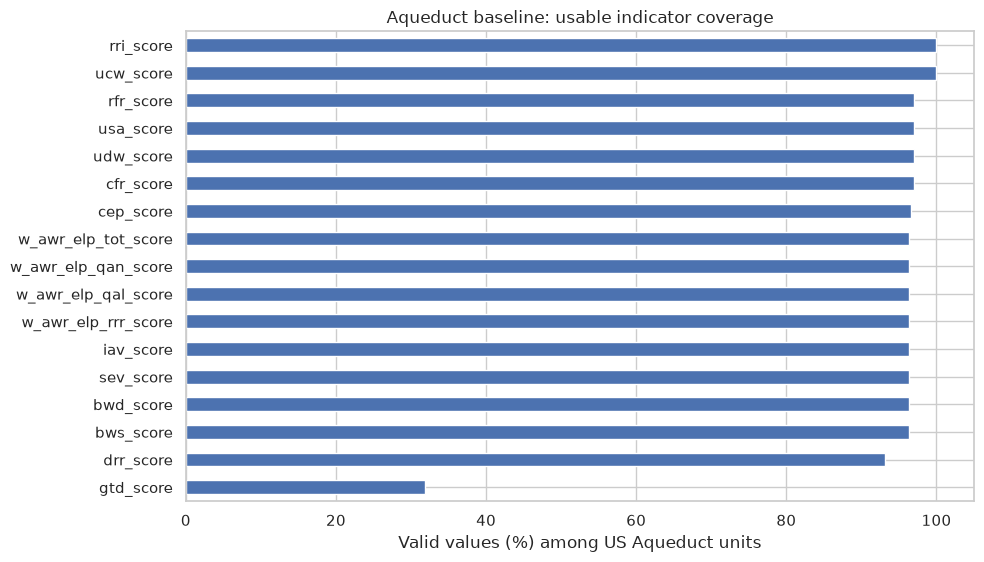

In [16]:
plot_cols = core_scores + elp_scores
coverage = clean_numeric[plot_cols].notna().mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(10, max(5, len(coverage)*0.34)))
coverage.plot.barh(ax=ax)
ax.set(xlabel="Valid values (%) among US Aqueduct units", title="Aqueduct baseline: usable indicator coverage", xlim=(0, 105))
fig.tight_layout(); fig.savefig(FIG_DIR / "01_us_indicator_coverage.png", dpi=180); plt.show()

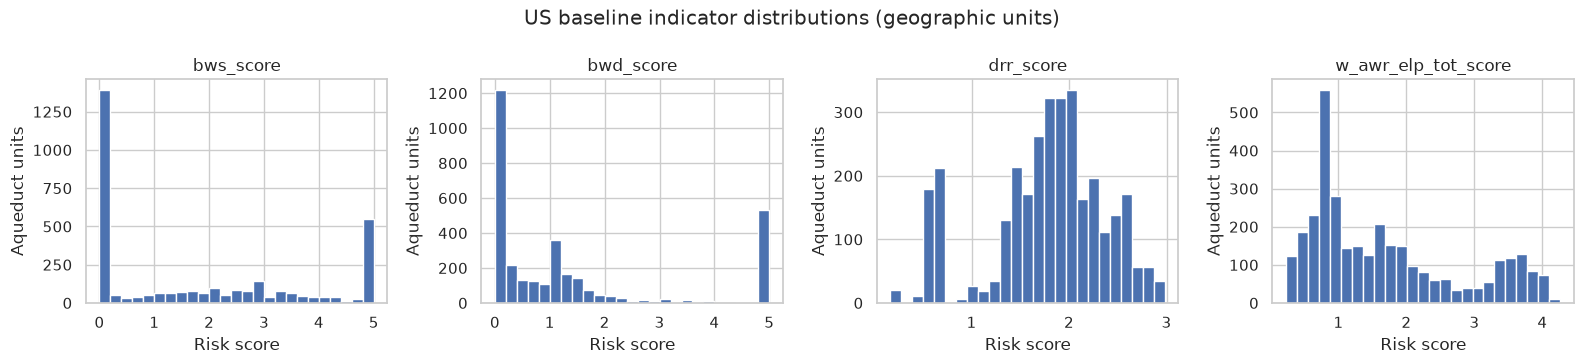

In [17]:
chosen = [c for c in ["bws_score", "bwd_score", "drr_score", "w_awr_elp_tot_score"] if c in clean_numeric]
if chosen:
    fig, axes = plt.subplots(1, len(chosen), figsize=(4*len(chosen), 3.7), squeeze=False)
    for ax, col in zip(axes[0], chosen):
        clean_numeric[col].dropna().hist(bins=25, ax=ax)
        ax.set(title=col, xlabel="Risk score", ylabel="Aqueduct units")
    fig.suptitle("US baseline indicator distributions (geographic units)")
    fig.tight_layout(); fig.savefig(FIG_DIR / "02_score_distributions.png", dpi=180); plt.show()

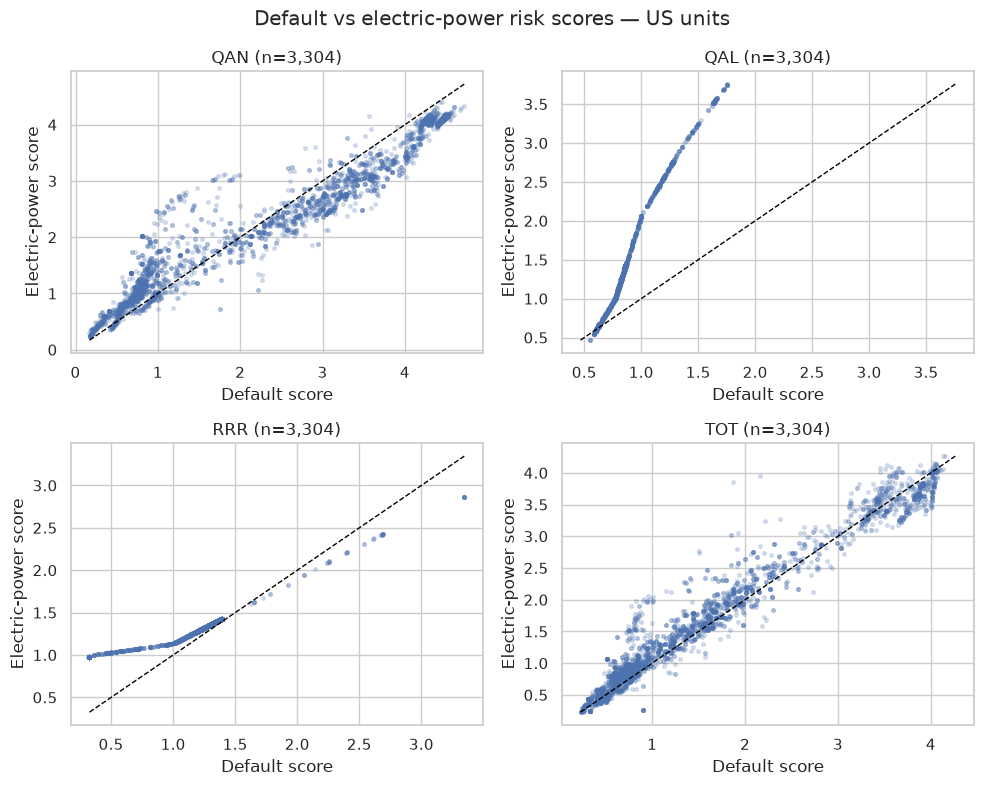

,composite,paired_n,mean_elp_minus_default,median_elp_minus_default,pearson_r
0,QAN,3304,-0.032431,-0.084424,0.970422
1,QAL,3304,0.767859,0.554300,0.991046
2,RRR,3304,0.155757,0.054257,0.959939
3,TOT,3304,0.099869,0.086208,0.979616


In [18]:
pairs = [(f"w_awr_def_{g}_score", f"w_awr_elp_{g}_score", g.upper()) for g in elp_types]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
comparison_stats = []
for ax, (d, e, label) in zip(axes.flat, pairs):
    if d not in clean_numeric or e not in clean_numeric:
        ax.set_visible(False); continue
    paired = clean_numeric[[d, e]].dropna()
    if paired.empty:
        ax.set_title(f"{label}: no valid pairs"); continue
    ax.scatter(paired[d], paired[e], s=7, alpha=0.2)
    lo, hi = paired.min().min(), paired.max().max()
    ax.plot([lo, hi], [lo, hi], linestyle="--", color="black", linewidth=1)
    ax.set(xlabel="Default score", ylabel="Electric-power score", title=f"{label} (n={len(paired):,})")
    comparison_stats.append({"composite": label, "paired_n": len(paired), "mean_elp_minus_default": (paired[e]-paired[d]).mean(), "median_elp_minus_default": (paired[e]-paired[d]).median(), "pearson_r": paired[d].corr(paired[e])})
fig.suptitle("Default vs electric-power risk scores — US units")
fig.tight_layout(); fig.savefig(FIG_DIR / "03_default_vs_elp.png", dpi=180); plt.show()
display(pd.DataFrame(comparison_stats))

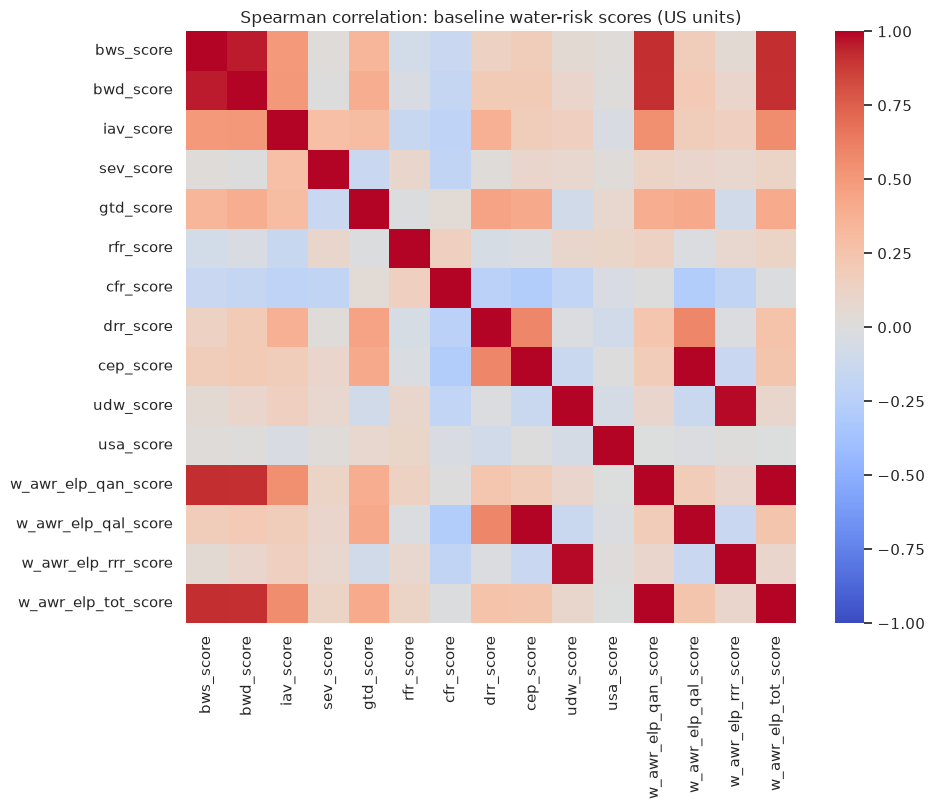

spearman_r
cep_score           w_awr_elp_qal_score    1.000000
w_awr_elp_qan_score w_awr_elp_tot_score    0.997773
udw_score           w_awr_elp_rrr_score    0.992144
bws_score           bwd_score              0.956868
                    w_awr_elp_tot_score    0.918933
                    w_awr_elp_qan_score    0.917424
bwd_score           w_awr_elp_tot_score    0.909628
                    w_awr_elp_qan_score    0.907922
drr_score           w_awr_elp_qal_score    0.589643
                    cep_score              0.586595
iav_score           w_awr_elp_tot_score    0.555882
                    w_awr_elp_qan_score    0.550359
bwd_score           iav_score              0.502390
bws_score           iav_score              0.492388
gtd_score           drr_score              0.452305

In [19]:
corr_cols = [c for c in core_scores + elp_scores if clean_numeric[c].notna().sum() >= 3 and clean_numeric[c].nunique(dropna=True) > 1]
if len(corr_cols) >= 2:
    corr = clean_numeric[corr_cols].corr(method="spearman", min_periods=3)
    fig, ax = plt.subplots(figsize=(max(8, len(corr_cols)*0.65), max(6, len(corr_cols)*0.55)))
    sns.heatmap(corr, vmin=-1, vmax=1, cmap="coolwarm", center=0, ax=ax)
    ax.set_title("Spearman correlation: baseline water-risk scores (US units)")
    fig.tight_layout(); fig.savefig(FIG_DIR / "04_score_correlations.png", dpi=180); plt.show()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("spearman_r")
    display(upper.loc[upper.abs().sort_values(ascending=False).index].head(15).to_frame())
else:
    print("Not enough nonconstant score columns for correlation plot")

## 6. Export clean **geographic-unit** baseline features
This export is **not facility-level**. Retain the original unit identifiers and geography so a verified spatial join can be performed. `wri_` prefixes prevent ambiguous column collisions. Do not use future projections in the baseline classifier without a separate temporal design.

In [20]:
# Keep all source geography / unit ID columns for traceability.
geo_cols = [c for c in us.columns if c.startswith("name_") or c.lower() in {"pfaf_id", "pfafid", "gid_0", "gid_1", "gid_2", "hydrobasin_id", "basin_id", "objectid", "id"}]
model_score_cols = core_scores + elp_scores  # no default composites by default: avoid duplicate aggregate representations
units_export = us[geo_cols].copy()
for c in model_score_cols:
    units_export[f"wri_{c}"] = clean_numeric[c]
units_export.to_csv(OUTPUT_DIR / "wri_aqueduct_baseline_us_units.csv", index=False)
print("Saved geographic-unit export:", units_export.shape)
print("ID/geography columns:", geo_cols)
print("Score columns:", model_score_cols)
print("Warning: geographic units are NOT facility rows")

Saved geographic-unit export: (3433, 22)
ID/geography columns: ['pfaf_id', 'gid_1', 'gid_0', 'name_0', 'name_1']
Score columns: ['bws_score', 'bwd_score', 'iav_score', 'sev_score', 'gtd_score', 'rfr_score', 'cfr_score', 'drr_score', 'ucw_score', 'cep_score', 'udw_score', 'usa_score', 'rri_score', 'w_awr_elp_qan_score', 'w_awr_elp_qal_score', 'w_awr_elp_rrr_score', 'w_awr_elp_tot_score']


## 7. Optional facility-level spatial join (required for the final ATLAS merge)
**Requires** a verified Aqueduct polygon layer and explicit matching key columns. The notebook will not guess a basin ID or assign data by nearest state. Set `BASIN_BOUNDARIES_PATH`, `BOUNDARY_JOIN_KEY`, and `AQUEDUCT_JOIN_KEY` in Section 1 after inspecting the GIS layer. You may need `pip install geopandas pyogrio shapely`.

In [21]:
if BASIN_BOUNDARIES_PATH is None:
    print("Spatial join NOT RUN: set the three spatial-join configuration fields in Section 1.")
    print("Available Aqueduct table key candidates:", [c for c in us.columns if any(x in c.lower() for x in ["pfaf", "basin", "id", "gid"])][:30])
else:
    import geopandas as gpd
    boundary_path = Path(BASIN_BOUNDARIES_PATH)
    boundaries = gpd.read_file(boundary_path)
    print("Boundary CRS:", boundaries.crs)
    print("Boundary columns:", boundaries.columns.tolist())
    display(boundaries.head(2))
    assert boundaries.crs is not None, "Boundary CRS missing; determine it from the data provider before continuing"
    assert BOUNDARY_JOIN_KEY in boundaries and AQUEDUCT_JOIN_KEY in us, "Explicit join keys must exist"
    print("Aqueduct key duplicate count:", us[AQUEDUCT_JOIN_KEY].duplicated().sum())
    print("Boundary key duplicate count:", boundaries[BOUNDARY_JOIN_KEY].duplicated().sum())
    print("Review these counts and confirm boundary/table geographic granularity before proceeding")

Spatial join NOT RUN: set the three spatial-join configuration fields in Section 1.
Available Aqueduct table key candidates: ['string_id', 'aq30_id', 'pfaf_id', 'gid_1', 'aqid', 'gid_0']


### 7a. Perform a guarded point-in-polygon extraction
This code only runs when configured. It refuses ambiguous geographic-unit IDs and duplicate polygon matches. Unmatched facilities remain in the output with missing WRI features; they are **not** assigned zero risk.

In [5]:
if BASIN_BOUNDARIES_PATH is None:
    print("Skipped facility export: no verified polygon layer configured.")
else:
    import geopandas as gpd
    registry = pd.read_csv(REGISTRY_PATH, dtype={"id": "string", "facility_id": "string"}, low_memory=False)
    if "facility_id" not in registry and "id" in registry:
        registry = registry.rename(columns={"id": "facility_id"})
    assert "facility_id" in registry
    assert registry["facility_id"].is_unique, "Facility IDs must be unique"
    lat_col = next((c for c in ["lat", "latitude"] if c in registry), None)
    lon_col = next((c for c in ["lon", "longitude", "lng"] if c in registry), None)
    assert lat_col and lon_col, "Registry must contain latitude/longitude columns"
    registry[lat_col] = pd.to_numeric(registry[lat_col], errors="coerce")
    registry[lon_col] = pd.to_numeric(registry[lon_col], errors="coerce")
    assert us[AQUEDUCT_JOIN_KEY].notna().all() and us[AQUEDUCT_JOIN_KEY].is_unique, "Aqueduct join key must be unique and non-null"
    # Normalize key type without changing non-string geographic IDs.
    units_keyed = units_export.copy()
    units_keyed[AQUEDUCT_JOIN_KEY] = us[AQUEDUCT_JOIN_KEY].astype("string").values
    boundaries = boundaries[[BOUNDARY_JOIN_KEY, "geometry"]].copy()
    boundaries[BOUNDARY_JOIN_KEY] = boundaries[BOUNDARY_JOIN_KEY].astype("string")
    assert boundaries[BOUNDARY_JOIN_KEY].notna().all() and boundaries[BOUNDARY_JOIN_KEY].is_unique, "Boundary key must be unique and non-null; investigate granularity first"
    assert boundaries.geometry.notna().all() and boundaries.geometry.is_valid.all(), "Fix invalid/missing boundary geometries before joining"
    valid_xy = registry[lat_col].between(-90, 90) & registry[lon_col].between(-180, 180)
    pts = gpd.GeoDataFrame(registry.loc[valid_xy, ["facility_id", lat_col, lon_col]].copy(), geometry=gpd.points_from_xy(registry.loc[valid_xy, lon_col], registry.loc[valid_xy, lat_col]), crs="EPSG:4326")
    hits = gpd.sjoin(pts.to_crs(boundaries.crs), boundaries, how="left", predicate="intersects")
    hit_counts = hits.groupby("facility_id")[BOUNDARY_JOIN_KEY].count()
    assert hit_counts.le(1).all(), "Some facilities intersect multiple polygons; resolve boundaries/overlaps before proceeding"
    matched = hits[["facility_id", BOUNDARY_JOIN_KEY]].rename(columns={BOUNDARY_JOIN_KEY: AQUEDUCT_JOIN_KEY})
    extracted = matched.merge(units_keyed[[AQUEDUCT_JOIN_KEY] + [f"wri_{c}" for c in model_score_cols]], on=AQUEDUCT_JOIN_KEY, how="left", validate="many_to_one", indicator=True)
    facility_wri = registry[["facility_id"]].merge(extracted.drop(columns="_merge"), on="facility_id", how="left", validate="one_to_one")
    assert len(facility_wri) == len(registry)
    audit_join = registry[["facility_id"]].merge(extracted[["facility_id", AQUEDUCT_JOIN_KEY, "_merge"]], on="facility_id", how="left", validate="one_to_one")
    audit_join["has_valid_coordinates"] = registry[lat_col].between(-90, 90) & registry[lon_col].between(-180, 180)
    audit_join["has_polygon_match"] = audit_join[AQUEDUCT_JOIN_KEY].notna()
    audit_join["has_aqueduct_attributes"] = audit_join["_merge"].eq("both")
    facility_wri.to_csv(OUTPUT_DIR / "wri_aqueduct_facility_features.csv", index=False)
    audit_join.to_csv(OUTPUT_DIR / "wri_aqueduct_spatial_join_audit.csv", index=False)
    print("Facility rows:", len(facility_wri), "Unique IDs:", facility_wri.facility_id.nunique())
    print("Valid polygon matches:", audit_join.has_polygon_match.sum())
    print("Aqueduct attribute matches:", audit_join.has_aqueduct_attributes.sum())
    print("Exported facility features and join audit")

Skipped facility export: no verified polygon layer configured.


## 8. Merge-readiness checks and interpretation
Run this when a facility export exists. **Keep the full IM3 registry as the left table** in the eventual USGS/EIA/WRI merge. Preserve missingness; do not treat missing water risk as low risk. Correlations and US-wide figures describe geographic units, not the facility-level training distribution.

In [6]:
facility_path = OUTPUT_DIR / "wri_aqueduct_facility_features.csv"
if facility_path.exists():
    fw = pd.read_csv(facility_path, dtype={"facility_id": "string"})
    assert fw.facility_id.is_unique
    print("Facility feature table:", fw.shape)
    print("Missingness (%) among facility rows:")
    display((fw.filter(regex=r"^wri_").isna().mean()*100).sort_values(ascending=False).round(1).to_frame("missing_pct"))
    print("Ready to left-merge on facility_id (after verifying registry row count).")
else:
    print("No facility-level WRI export yet. Obtain verified Aqueduct polygons + join key; do NOT merge geographic-unit rows directly.")
print("Figure files:", sorted(p.name for p in FIG_DIR.glob("*.png")))

No facility-level WRI export yet. Obtain verified Aqueduct polygons + join key; do NOT merge geographic-unit rows directly.
Figure files: ['01_us_indicator_coverage.png', '02_score_distributions.png', '03_default_vs_elp.png', '04_score_correlations.png']


## Modeling notes / limitations

- **Baseline only:** `future` projections and monthly series are inventoried but not included in the baseline export. If used later, define time/scenario and temporal alignment explicitly.
- **Score vs raw:** Scores are comparable ordinal/standardized risk representations; raw variables have heterogeneous units and may require different preprocessing. Do not indiscriminately standardize sentinel codes.
- **Sector weighting:** ELP scores may be relevant to electricity-intensive facilities, but that is a hypothesis to test against default scores in an ablation, not proof of better classification.
- **Geographic shortcut learning:** Water-risk features can act as proxies for region/state. Evaluate geographically separated splits and feature ablations; high correlation is not causation.
- **Missingness:** Report both Aqueduct geographic-unit coverage and facility-level spatial match coverage. Never fill missing values with 0 before understanding why they are missing.
- **Spatial resolution:** A basin-level risk score shared by multiple facilities is expected; it is not independent site-level measurement.


## this is inspecting the geodatabase layers

In [7]:
from pathlib import Path

base = Path(
    "/mnt/c/Users/attho/OneDrive/Desktop/College/ACM ATLAS/"
    "aqueduct-4-0-water-risk-data"
)

gdb_folders = list(base.rglob("*.gdb"))

print("Found geodatabases:")
for path in gdb_folders:
    print(path)

import geopandas as gpd

if gdb_folders:
    gdb_path = gdb_folders[0]
    print("Using:", gdb_path)
    display(gpd.list_layers(gdb_path))
else:
    print("No .gdb folders found. Check the base directory.")

Found geodatabases:
/mnt/c/Users/attho/OneDrive/Desktop/College/ACM ATLAS/aqueduct-4-0-water-risk-data/Aqueduct40_waterrisk_download_Y2023M07D05/GDB/Aq40_Y2023D07M05.gdb
Using: /mnt/c/Users/attho/OneDrive/Desktop/College/ACM ATLAS/aqueduct-4-0-water-risk-data/Aqueduct40_waterrisk_download_Y2023M07D05/GDB/Aq40_Y2023D07M05.gdb


,name,geometry_type
0,baseline_annual,MultiPolygon
1,baseline_monthly,MultiPolygon
2,future_annual,MultiPolygon


In [8]:
import geopandas as gpd

wri_geo = gpd.read_file(
    gdb_path,
    layer="baseline_annual"
)

assert all(col in wri_geo.columns for col in risk_cols)
print("Shape:", wri_geo.shape)
print("CRS:", wri_geo.crs)

print("\nPotential geographic identifiers:")
print([
    c for c in wri_geo.columns
    if any(k in c.lower() for k in ["id", "pfaf", "hydro", "name"])
])

print("\nFirst 5 rows:")
display(wri_geo.drop(columns="geometry").head())


expected_scores = [
    "bws_score", "bwd_score", "iav_score", "sev_score",
    "gtd_score", "rfr_score", "cfr_score", "drr_score",
    "ucw_score", "cep_score", "udw_score", "usa_score",
    "rri_score",
    "w_awr_elp_qan_score", "w_awr_elp_qal_score",
    "w_awr_elp_rrr_score", "w_awr_elp_tot_score"
]

print("Expected scores:", len(expected_scores))
print("Present in source:", len([c for c in expected_scores if c in wri_geo.columns]))
print("Missing from source:", [c for c in expected_scores if c not in wri_geo.columns])
print("Source CRS:", wri_geo.crs)

/home/atthota/venvs/atlas/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined
  return ogr_read(


Shape: (68506, 237)
CRS: EPSG:4326

Potential geographic identifiers:
['string_id', 'aq30_id', 'string_id_1', 'aq30_id_1', 'pfaf_id', 'gid_1', 'aqid', 'gid_0', 'name_0', 'name_1']

First 5 rows:


,string_id,aq30_id,Shape_Leng,string_id_1,aq30_id_1,pfaf_id,gid_1,aqid,gid_0,name_0,...,w_awr_tex_rrr_score,w_awr_tex_rrr_cat,w_awr_tex_rrr_label,w_awr_tex_tot_raw,w_awr_tex_tot_score,w_awr_tex_tot_cat,w_awr_tex_tot_label,w_awr_tex_tot_weight_fraction,Shape_Length,Shape_Area
0,111011-EGY.11_1-3365,0.0,0.084893,111011-EGY.11_1-3365,0,111011,EGY.11_1,3365,EGY,Egypt,...,2.163858,2.0,Medium - High (2-3),2.509062,3.705279,3.0,High (3-4),0.877551,0.084893,0.000399
1,111011-EGY.15_1-3365,1.0,2.105655,111011-EGY.15_1-3365,1,111011,EGY.15_1,3365,EGY,Egypt,...,2.163858,2.0,Medium - High (2-3),2.509062,3.705279,3.0,High (3-4),0.877551,2.105655,0.171831
2,111011-EGY.15_1-None,2.0,0.893735,111011-EGY.15_1-None,2,111011,EGY.15_1,-9999,EGY,Egypt,...,2.163858,2.0,Medium - High (2-3),2.509062,3.705279,3.0,High (3-4),0.877551,0.893735,0.002813
3,111011-None-3365,3.0,0.051464,111011-None-3365,3,111011,-9999,3365,NaN,NaN,...,-9999.000000,-9999.0,No data,-9999.000000,-9999.000000,-9999.0,No data,0.551020,0.051464,0.000053
4,111011-None-None,4.0,0.929535,111011-None-None,4,111011,-9999,-9999,NaN,NaN,...,-9999.000000,-9999.0,No data,-9999.000000,-9999.000000,-9999.0,No data,0.551020,0.929535,0.001253


Expected scores: 17
Present in source: 17
Missing from source: []
Source CRS: EPSG:4326


## filters for US only

In [9]:
# Keep US polygons
wri_us_geo = wri_geo[
    wri_geo["gid_0"] == "USA"
].copy()

# Geographic identifiers and baseline risk indicators
geo_cols = [
    "string_id",
    "pfaf_id",
    "aqid",
    "gid_0",
    "name_0",
    "name_1"
]

risk_cols = [
    "bws_score",
    "bwd_score",
    "iav_score",
    "sev_score",
    "gtd_score",
    "rfr_score",
    "cfr_score",
    "drr_score",
    "ucw_score",  # Restored
    "cep_score",
    "udw_score",
    "usa_score",
    "rri_score",  # Restored
    "w_awr_elp_qan_score",
    "w_awr_elp_qal_score",
    "w_awr_elp_rrr_score",
    "w_awr_elp_tot_score"
]

wri_us_geo = wri_us_geo[
    geo_cols + risk_cols + ["geometry"]
]

print("US polygons:", len(wri_us_geo))
print("CRS:", wri_us_geo.crs)
display(wri_us_geo.head(3))

print("Shape:", wri_us_geo.shape)

print("\nCore scores present:")
print([c for c in core_scores if c in wri_us_geo.columns])

print("\nMissing core scores:")
print([c for c in core_scores if c not in wri_us_geo.columns])

US polygons: 3433
CRS: EPSG:4326


,string_id,pfaf_id,aqid,gid_0,name_0,name_1,bws_score,bwd_score,iav_score,sev_score,...,ucw_score,cep_score,udw_score,usa_score,rri_score,w_awr_elp_qan_score,w_awr_elp_qal_score,w_awr_elp_rrr_score,w_awr_elp_tot_score,geometry
29003,355000-USA.2_1-1047,355000,1047,USA,United States,Alaska,0.0,0.000184,0.934825,0.38538,...,0.880683,-9999.0,2.710323,4.262706,0.88,0.236505,0.607368,2.864561,0.259198,"MULTIPOLYGON (((172.77884 53.0108, 172.78889 5..."
29004,355000-USA.2_1-1064,355000,1064,USA,United States,Alaska,0.0,0.000184,0.934825,0.38538,...,0.880683,-9999.0,2.710323,4.262706,0.88,0.236505,0.607368,2.864561,0.259198,"MULTIPOLYGON (((173.77358 52.50726, 173.75945 ..."
29005,355000-USA.2_1-1079,355000,1079,USA,United States,Alaska,0.0,0.000184,0.934825,0.38538,...,0.880683,-9999.0,2.710323,4.262706,0.88,0.236505,0.607368,2.864561,0.259198,"MULTIPOLYGON (((177.61632 52.12666, 177.62484 ..."


Shape: (3433, 24)

Core scores present:
['bws_score', 'bwd_score', 'iav_score', 'sev_score', 'gtd_score', 'rfr_score', 'cfr_score', 'drr_score', 'ucw_score', 'cep_score', 'udw_score', 'usa_score', 'rri_score']

Missing core scores:
[]


## clean sentinel values

In [10]:
import pandas as pd

for col in risk_cols:
    wri_us_geo[col] = pd.to_numeric(
        wri_us_geo[col], errors="coerce"
    ).replace([-9999, 9999], float("nan"))

print(
    wri_us_geo[risk_cols]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

gtd_score              68.161957
drr_score               6.845325
bws_score               3.699388
iav_score               3.699388
bwd_score               3.699388
sev_score               3.699388
w_awr_elp_qal_score     3.699388
w_awr_elp_rrr_score     3.699388
w_awr_elp_tot_score     3.699388
w_awr_elp_qan_score     3.699388
cep_score               3.378969
rfr_score               2.971162
cfr_score               2.971162
usa_score               2.971162
udw_score               2.971162
ucw_score               0.000000
rri_score               0.000000
dtype: float64


In [11]:
# temp cell

validation = pd.DataFrame({
    "missing_pct": wri_us_geo[risk_cols].isna().mean() * 100,
    "min": wri_us_geo[risk_cols].min(),
    "max": wri_us_geo[risk_cols].max(),
    "unique_values": wri_us_geo[risk_cols].nunique(),
    "sentinels_remaining": wri_us_geo[risk_cols]
        .isin([-9999, 9999]).sum(),
    "out_of_range": (
        (wri_us_geo[risk_cols] < 0) |
        (wri_us_geo[risk_cols] > 5)
    ).sum()
})

display(validation)

,missing_pct,min,max,unique_values,sentinels_remaining,out_of_range
bws_score,3.699388,0.000000,5.000000,474,0,0
bwd_score,3.699388,0.000000,5.000000,1027,0,0
iav_score,3.699388,0.334977,5.000000,1215,0,0
sev_score,3.699388,0.139779,4.788465,1241,0,0
gtd_score,68.161957,0.000000,3.297948,27,0,0
rfr_score,2.971162,0.000000,4.074279,1081,0,0
cfr_score,2.971162,0.000000,4.064478,125,0,0
drr_score,6.845325,0.168471,2.981934,1179,0,0
ucw_score,0.000000,0.880683,0.880683,1,0,0
cep_score,3.378969,0.625253,4.290276,691,0,0


In [12]:
print("Shape:", wri_us_geo.shape)
print("CRS:", wri_us_geo.crs)

print("Null geometries:", wri_us_geo.geometry.isna().sum())
print("Empty geometries:", wri_us_geo.geometry.is_empty.sum())
print("Invalid geometries:", (~wri_us_geo.geometry.is_valid).sum())

print("Geometry types:")
print(wri_us_geo.geometry.geom_type.value_counts())

print("Duplicate string_id:", wri_us_geo["string_id"].duplicated().sum())
print("Countries:", wri_us_geo["gid_0"].value_counts(dropna=False))

Shape: (3433, 24)
CRS: EPSG:4326
Null geometries: 0
Empty geometries: 0
Invalid geometries: 63
Geometry types:
MultiPolygon    3433
Name: count, dtype: int64
Duplicate string_id: 0
Countries: gid_0
USA    3433
Name: count, dtype: int64


## invalid geometry check

**Inspect first then repai or remove:** We have to make sure to inspect first because there could be fixes that casn be made

In [13]:
from shapely.validation import explain_validity

invalid_geo = wri_us_geo.loc[
    ~wri_us_geo.geometry.is_valid
].copy()

invalid_geo["invalid_reason"] = (
    invalid_geo.geometry.apply(explain_validity)
)

print("Invalid geometries:", len(invalid_geo))

print("\nInvalidity categories:")
print(
    invalid_geo["invalid_reason"]
    .str.split("[")
    .str[0]
    .value_counts()
)

display(
    invalid_geo[
        ["string_id", "name_1", "invalid_reason"]
    ].head(10)
)

Invalid geometries: 63

Invalidity categories:
invalid_reason
Ring Self-intersection    63
Name: count, dtype: int64


,string_id,name_1,invalid_reason
53539,731000-USA.33_1-1383,New York,Ring Self-intersection[-73.7687854768682 40.62...
53540,731000-USA.33_1-None,New York,Ring Self-intersection[-73.5983950279082 40.62...
53564,731140-USA.20_1-1158,Maine,Ring Self-intersection[-69.8838907891286 43.99...
53570,731150-USA.20_1-None,Maine,Ring Self-intersection[-70.0320148480068 43.75...
53576,731170-USA.20_1-1158,Maine,Ring Self-intersection[-70.6416384380634 43.12...
53579,731170-USA.30_1-1158,New Hampshire,Ring Self-intersection[-70.8903738675599 43.13...
53590,731190-USA.22_1-1158,Massachusetts,Ring Self-intersection[-70.6881255907234 42.63...
53597,731190-USA.40_1-None,Rhode Island,Ring Self-intersection[-71.5882787686502 41.19...
53599,731190-USA.7_1-None,Connecticut,Ring Self-intersection[-72.002847672582 41.324...
53656,731503-USA.33_1-1402,New York,Ring Self-intersection[-74.1968994145763 40.57...


## geometry repair trial

In [14]:
from shapely.validation import make_valid

repaired = invalid_geo.geometry.apply(make_valid)

print("Original invalid:", (~invalid_geo.geometry.is_valid).sum())
print("Still invalid after repair:", (~repaired.is_valid).sum())
print("Empty after repair:", repaired.is_empty.sum())

print("\nRepaired geometry types:")
print(repaired.geom_type.value_counts())

Original invalid: 63
Still invalid after repair: 0
Empty after repair: 0

Repaired geometry types:
MultiPolygon    58
Polygon          5
Name: count, dtype: int64


## measuring what changed

In [15]:
import geopandas as gpd

original_proj = invalid_geo.to_crs("EPSG:5070")

repaired_proj = gpd.GeoSeries(
    repaired,
    index=invalid_geo.index,
    crs=wri_us_geo.crs
).to_crs("EPSG:5070")

area_comparison = pd.DataFrame({
    "original_area": original_proj.geometry.area,
    "repaired_area": repaired_proj.area
})

area_comparison["relative_change_pct"] = (
    (
        area_comparison["repaired_area"]
        - area_comparison["original_area"]
    ).abs()
    / area_comparison["original_area"].replace(0, float("nan"))
    * 100
)

print("Maximum area change (%):",
      area_comparison["relative_change_pct"].max())

print("Median area change (%):",
      area_comparison["relative_change_pct"].median())

print("Geometries with >1% area change:",
      (area_comparison["relative_change_pct"] > 1).sum())

print("Zero-area originals:",
      (area_comparison["original_area"] == 0).sum())

Maximum area change (%): 4.203497796754942e-13
Median area change (%): 3.582560617525249e-14
Geometries with >1% area change: 0
Zero-area originals: 0


## geographic footprint difference 

In [16]:
footprint_diff = []

for idx in invalid_geo.index:
    original = original_proj.loc[idx].geometry
    fixed = repaired_proj.loc[idx]

    diff_area = original.symmetric_difference(fixed).area

    footprint_diff.append(diff_area)

footprint_diff = pd.Series(
    footprint_diff,
    index=invalid_geo.index,
    name="difference_m2"
)

print("Maximum footprint difference (m²):",
      footprint_diff.max())

print("Median footprint difference (m²):",
      footprint_diff.median())

print("Geometries with difference > 1 m²:",
      (footprint_diff > 1).sum())

Maximum footprint difference (m²): 0.0
Median footprint difference (m²): 0.0
Geometries with difference > 1 m²: 0


## applying geometry repair

In [17]:
from shapely.geometry import MultiPolygon

# Standardize repaired Polygon geometries to MultiPolygon
repaired_multi = repaired.apply(
    lambda geom: MultiPolygon([geom])
    if geom.geom_type == "Polygon"
    else geom
)

# Replace only the 63 invalid geometries
wri_us_geo.loc[invalid_geo.index, "geometry"] = repaired_multi

# Verify the resulting geometry column
print("Shape:", wri_us_geo.shape)
print("Invalid geometries:", (~wri_us_geo.geometry.is_valid).sum())
print("Empty geometries:", wri_us_geo.geometry.is_empty.sum())
print("Geometry types:")
print(wri_us_geo.geometry.geom_type.value_counts())

Shape: (3433, 24)
Invalid geometries: 0
Empty geometries: 0
Geometry types:
MultiPolygon    3433
Name: count, dtype: int64


In [18]:
from shapely.validation import make_valid
from shapely.geometry import MultiPolygon

# Identify invalid geometries directly from the cleaned dataset
invalid_mask = ~wri_us_geo.geometry.is_valid

print("Invalid geometries before repair:", invalid_mask.sum())

# Repair only invalid geometries
for idx in wri_us_geo.index[invalid_mask]:
    geom = make_valid(wri_us_geo.at[idx, "geometry"])

    if geom.geom_type == "Polygon":
        geom = MultiPolygon([geom])

    wri_us_geo.at[idx, "geometry"] = geom

# Verify repairs
assert wri_us_geo.geometry.is_valid.all()
assert (wri_us_geo.geometry.geom_type == "MultiPolygon").all()

print("Invalid geometries after repair:",
      (~wri_us_geo.geometry.is_valid).sum())

print("Final shape:", wri_us_geo.shape)

Invalid geometries before repair: 0
Invalid geometries after repair: 0
Final shape: (3433, 24)


# some checks for spatial join

In [19]:
print("wri_us_geo exists:", "wri_us_geo" in globals())
print("Kernel variables:")
%whos

wri_us_geo exists: True
Kernel variables:
Variable                Type            Data/Info
-------------------------------------------------
AQUEDUCT_DIR            PosixPath       /mnt/c/Users/attho/OneDri<...>_download_Y2023M07D05/CVS
AQUEDUCT_JOIN_KEY       NoneType        None
BASIN_BOUNDARIES_PATH   NoneType        None
BOUNDARY_JOIN_KEY       NoneType        None
FIG_DIR                 PosixPath       /mnt/c/Users/attho/OneDri<...>ata/processed/wri_figures
MultiPolygon            type            <class 'shapely.geometry.<...>ltipolygon.MultiPolygon'>
OUTPUT_DIR              PosixPath       /mnt/c/Users/attho/OneDri<...>TLAS/ATLAS/Data/processed
Path                    type            <class 'pathlib.Path'>
REGISTRY_PATH           PosixPath       /mnt/c/Users/attho/OneDri<...>im3_facility_registry.csv
REPO                    PosixPath       /mnt/c/Users/attho/OneDri<...>p/College/ACM ATLAS/ATLAS
SENTINELS_TO_MASK       list            n=2
annual                  DataFrame       

## final verification

In [20]:
print("Shape:", wri_us_geo.shape)
print("CRS:", wri_us_geo.crs.to_epsg())

print("Scores present:",
      len([c for c in expected_scores if c in wri_us_geo.columns]))

print("Missing scores:",
      [c for c in expected_scores if c not in wri_us_geo.columns])

print("Invalid geometries:",
      (~wri_us_geo.geometry.is_valid).sum())

print("Empty geometries:",
      wri_us_geo.geometry.is_empty.sum())

Shape: (3433, 24)
CRS: 4326
Scores present: 17
Missing scores: []
Invalid geometries: 0
Empty geometries: 0


In [ ]:
from pathlib import Path

current_save_path = Path.cwd() / "wri_us_cleaned.parquet"
processed_save_path = OUTPUT_DIR / "wri_us_cleaned.parquet"

print("Current save path:", current_save_path)
print("File exists:", current_save_path.exists())

print("\nProcessed save path:", processed_save_path)
print("File exists:", processed_save_path.exists())

print("\nSame destination:",
      current_save_path.resolve() == processed_save_path.resolve())

Current save path: /mnt/c/Users/attho/OneDrive/Desktop/College/ACM ATLAS/ATLAS/wri_us_cleaned.parquet
File exists: True

Processed save path: /mnt/c/Users/attho/OneDrive/Desktop/College/ACM ATLAS/ATLAS/Data/processed/wri_us_cleaned.parquet
File exists: False

Same destination: False


## inspecting the existing file 

In [48]:
import geopandas as gpd

existing_wri = gpd.read_parquet(current_save_path)

print("Existing Parquet shape:", existing_wri.shape)
print("Existing Parquet CRS:", existing_wri.crs)

print(
    "WRI scores present:",
    len([c for c in expected_scores if c in existing_wri.columns])
)

print(
    "Missing scores:",
    [c for c in expected_scores if c not in existing_wri.columns]
)

print(
    "Invalid geometries:",
    (~existing_wri.geometry.is_valid).sum()
)

Existing Parquet shape: (3433, 22)
Existing Parquet CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "dire

In [21]:
from pathlib import Path

output_path = OUTPUT_DIR / "wri_us_cleaned.parquet"

assert not output_path.exists(), f"File already exists: {output_path}"
assert wri_us_geo.shape == (3433, 24)
assert wri_us_geo.crs.to_epsg() == 4326
assert all(c in wri_us_geo.columns for c in expected_scores)
assert wri_us_geo.geometry.is_valid.all()

output_path.parent.mkdir(parents=True, exist_ok=True)

wri_us_geo.to_parquet(output_path)

print("Saved to:", output_path)
print("Shape:", wri_us_geo.shape)

Saved to: /mnt/c/Users/attho/OneDrive/Desktop/College/ACM ATLAS/ATLAS/Data/processed/wri_us_cleaned.parquet
Shape: (3433, 24)


## reload verifaction for fixed parquet

In [22]:
import geopandas as gpd

saved_wri = gpd.read_parquet(output_path)

print("Reloaded shape:", saved_wri.shape)
print("CRS:", saved_wri.crs.to_epsg())

print("Scores present:",
      len([c for c in expected_scores if c in saved_wri.columns]))

print("Missing scores:",
      [c for c in expected_scores if c not in saved_wri.columns])

print("Invalid geometries:",
      (~saved_wri.geometry.is_valid).sum())

print("Empty geometries:",
      saved_wri.geometry.is_empty.sum())

print("Geometry types:")
print(saved_wri.geometry.geom_type.value_counts())

Reloaded shape: (3433, 24)
CRS: 4326
Scores present: 17
Missing scores: []
Invalid geometries: 0
Empty geometries: 0
Geometry types:
MultiPolygon    3433
Name: count, dtype: int64


In [23]:
import pandas as pd

pd.testing.assert_frame_equal(
    wri_us_geo.sort_index(),
    saved_wri.sort_index(),
    check_dtype=True,
    check_exact=True
)

print("PASS: Saved Parquet matches in-memory GeoDataFrame exactly.")

PASS: Saved Parquet matches in-memory GeoDataFrame exactly.


## resolving indicator count issue

**Indicators:** As mentioned by the wri aquaduct 4.0, there are 13 main indicators that we have to pull. 11 with 2 elp scores. 

In [30]:
print("UCW columns:")
print([c for c in wri_us_geo.columns if "ucw" in c.lower()])

print("\nRRI columns:")
print([c for c in wri_us_geo.columns if "rri" in c.lower()])


# Replace wri_geo with the actual variable holding
# the original, unfiltered baseline_annual layer

print([
    col for col in wri_geo.columns
    if "ucw" in col.lower() or "rri" in col.lower()
])

UCW columns:
[]

RRI columns:
[]
['ucw_raw', 'ucw_score', 'ucw_cat', 'ucw_label', 'rri_raw', 'rri_score', 'rri_cat', 'rri_label']


## sanity check

In [31]:
expected_scores = [
    "bws_score", "bwd_score", "iav_score",
    "sev_score", "gtd_score", "rfr_score",
    "cfr_score", "drr_score", "cep_score",
    "udw_score", "usa_score", "ucw_score",
    "rri_score"
]

actual_scores = [
    c for c in wri_us_geo.columns
    if c.endswith("_score")
]

print("Shape:", wri_us_geo.shape)
print("CRS:", wri_us_geo.crs)
print("Score columns:", len(actual_scores))
print("Missing core indicators:",
      set(expected_scores) - set(actual_scores))
print("Geometry types:",
      wri_us_geo.geometry.geom_type.value_counts())

Shape: (3433, 22)
CRS: EPSG:4326
Score columns: 15
Missing core indicators: {'rri_score', 'ucw_score'}
Geometry types: MultiPolygon    3433
Name: count, dtype: int64


In [32]:
import pandas as pd
import numpy as np

scores = wri_us_geo[score_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Values outside the valid WRI score range
out_of_range = (
    (scores < 0) | (scores > 5)
).sum()

audit = pd.DataFrame({
    "missing_pct": scores.isna().mean() * 100,
    "min": scores.min(),
    "max": scores.max(),
    "unique_values": scores.nunique(),
    "out_of_range": out_of_range
})

display(audit.round(3))

NameError: name 'score_cols' is not defined